# Homework 4

Solution to the fourth homework of the Machine Learning Zoomcamp 2026, in which I explore the lead-scoring dataset, evaluate the feature importance of the numerical variables using the ROC AUC, train logistic regression models and use different metrics to evaluate these models.

## Import Libraries and Load the Data

Import NumPy, pandas, seaborn, matplotlib and scikit-learn, load the dataset and inspect the first rows.

In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv")

In [3]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


## Data Exploration

Inspect descriptive statistics, check missing values and fill the missing values of the categorical variables with 'NA' and of the numerical variables with '0.0'.

In [4]:
df.describe()

,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
count,4631.000000,5000.000000,5000.000000,4965.000000,5000.000000
mean,54533.212049,2.089400,4.472600,0.494767,0.576600
std,21245.661710,1.188987,2.435906,0.199431,0.494147
min,12000.000000,0.000000,0.000000,0.010000,0.000000
25%,40458.500000,1.000000,3.000000,0.360000,0.000000
50%,55051.000000,2.000000,4.000000,0.490000,1.000000
75%,71252.500000,3.000000,6.000000,0.630000,1.000000
max,109886.000000,6.000000,13.000000,0.990000,1.000000


In [5]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [6]:
df[['lead_source','industry','employment_status','location']] = df[['lead_source','industry','employment_status','location']].fillna('NA')

In [7]:
df[['annual_income','lead_score']] = df[['annual_income','lead_score']].fillna(0.0)

In [8]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

## Split the Data

Split the data into training, validation and test datasets.

In [9]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [10]:
y_train = df_train.converted.values
y_val = df_val.converted.values

In [11]:
del df_train['converted']
del df_val['converted']

In [12]:
numerical = ['annual_income','number_of_courses_viewed','interaction_count','lead_score']
categorical = ['lead_source','industry','employment_status','location']

## ROC AUC Feature Importance

Use ROC AUC to evaluate feature importance of numerical variables. On the train dataset, for each numerical variable, use it as score and compute the AUC with the ```y``` variable as ground truth (Q1).

In [13]:
auc_dic = {}

for feat in numerical:

    y_score = df_train[feat]
    x = roc_auc_score(y_train,y_score)
    if x >= 0.5:
        auc_dic[feat] = x
    else:
        y_score = -df_train[feat]
        auc_dic[feat] = roc_auc_score(y_train,y_score)
        

auc_dic

{'annual_income': 0.6081977776250831,
 'number_of_courses_viewed': 0.7229894623989618,
 'interaction_count': 0.7649203047563227,
 'lead_score': 0.7882254810906102}

The numerical value that has the highest AUC is ```lead_score```.

## Train the Model

Train a logistic regression model and compute its AUC on the validation dataset (Q2).

In [14]:
train_dict = df_train[categorical + numerical].to_dict(orient='records')

In [15]:
dv = DictVectorizer(sparse=False)
dv.fit(train_dict)

DictVectorizer(sparse=False)

In [16]:
X_train = dv.transform(train_dict)

In [17]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000, solver='liblinear')

In [18]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

In [19]:
y_pred = model.predict_proba(X_val)[:, 1]

In [20]:
round(roc_auc_score(y_val,y_pred),3)

0.732

The AUC of this model on the validation dataset is 0.732.

## Precision and Recall

Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01. For each threshold, compute precision and recall and plot these two metrics. Check at which threshold precision and recall curves intersect (Q3).

In [21]:
thresholds = np.linspace(0, 1, 101)

precisions = []

recalls = []

for t in thresholds:

    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    if tp + fp != 0:
        precision = tp / (tp + fp)
    else:
        precision = np.nan

    if tp + fn != 0:
        recall = tp / (tp + fn)
    else:
        recall = np.nan

    precisions.append(precision)
    recalls.append(recall)

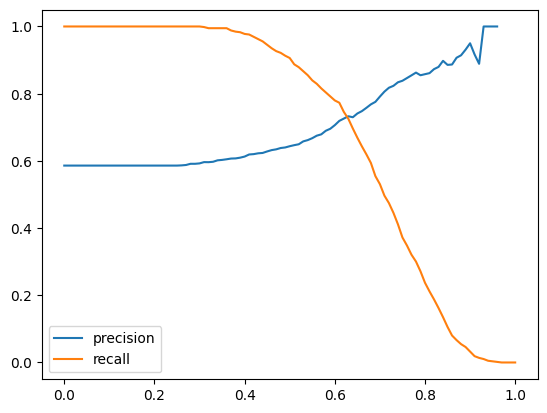

In [22]:
plt.plot(thresholds, precisions, label='precision')
plt.plot(thresholds, recalls, label='recall')
plt.legend()

In [23]:
Delta_min = 1

for i in range(len(precisions)):
    if not (precisions[i] == 0 and recalls[i] == 0) and not np.isnan(precisions[i]) and not np.isnan(recalls[i]):
        Delta = np.abs(precisions[i]-recalls[i])
        if Delta < Delta_min:
            Delta_min = Delta
            i_min = i

thresholds[i_min]

0.63

Precision and recall curves intersect at a threshold of 0.63.

## F1 Score

Compute the F1 score of the model on all thresholds from 0.0 to 1.0 with step 0.01. Plot these metric and check at which threshold the F1 score is maximal (Q4).

In [24]:
thresholds = np.linspace(0, 1, 101)

f1s = []

for t in thresholds:

    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    if tp + fp != 0 and tp + fn != 0:
        precision = tp / (tp + fp)
        recall = tp / (tp + fn)
        f1 = 2 * precision * recall / (precision + recall)
    else:
        f1 = np.nan

    f1s.append(f1)

Text(0, 0.5, 'F1')

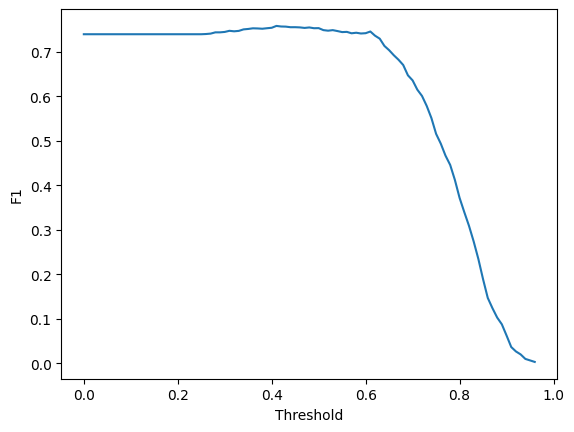

In [25]:
plt.plot(thresholds, f1s)
plt.xlabel("Threshold")
plt.ylabel("F1")

In [26]:
F1_max = 0

for i in range(len(f1s)):
    if f1s[i] > F1_max:
        F1_max = f1s[i]
        i_max = i

round(thresholds[i_max],3)

0.41

F1 is maximal at a threshold of 0.41.

## Cross Validation

Evaluate the model on 5 different folds. For each fold, use AUC to evaluate the model on the validation dataset. Compute the standard deviation of the 5 AUC results (Q5).

In [27]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []


for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train)

    dicts_val = df_val[categorical + numerical].to_dict(orient='records')
    X_val = dv.transform(dicts_val)
    y_pred = model.predict_proba(X_val)[:, 1]

    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

round(np.std(scores),3)

0.007

The standard deviation of the scores across different folds is 0.007.

## Hyperparameter Tuning

Evaluate the model on 5 different folds for three different values of the regularization parameter ```C```. For each fold, use AUC to evaluate the model on the validation dataset. Check for which value of ```C``` is the largest mean AUC result obtained (Q6).

In [28]:
for C in [0.000001, 0.001, 1]:

    kfold = KFold(n_splits=5, shuffle=True, random_state=1)

    scores = []


    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dicts = df_train[categorical + numerical].to_dict(orient='records')

        dv = DictVectorizer(sparse=False)
        X_train = dv.fit_transform(dicts)

        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model.fit(X_train, y_train)

        dicts_val = df_val[categorical + numerical].to_dict(orient='records')
        X_val = dv.transform(dicts_val)
        y_pred = model.predict_proba(X_val)[:, 1]

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=1 0.732 +- 0.007


```C=0.001``` leads to the best mean ROC AUC.